In [ ]:
#Random  module
import random
res = random.randint(1,10)
print(res)

9


In [ ]:
#simulate tossing coin
import random
res = random.choice(["H","T"])
print(res)


H


In [ ]:
#simulate for 100 times
import random
heads = 0
tails = 0
for i in range(100):
  res = random.choice(["Head","Tail"])
  if res == "Head":
    heads+=1
  else:
    tails+=1

print("Number of heads: ",heads)
print("Number of tails: ",tails)
print("Total tosses: ",heads+tails)
print("Probability of head: ",heads/100)

Number of heads:  49
Number of tails:  51
Total tosses:  100
Probability of head:  0.49


In [ ]:
#sampling without replcement = do not put it back
import random
population = [1,2,3,4,5]
res = random.sample(population,3)#select any 3 items from the population whic are distinct
print(res)

[5, 4, 2]


In [ ]:
#sampling with replacemnet = put it back
import random
population = [1,2,3,4,5]
res = random.choices(population,k=3)
print(res)

[1, 3, 1]


In [ ]:
#multiplication rule = tells about probability of 2 events happening together. p(a intersection b) = p(a)*p(b|a) where p(b|a) = p(b) if both events are independent

#rolling 2 dice and the probability of getting odd number in both together
import random
trails = 100
success = 0
for i in range(trails):
  dice1 = random.randint(1,6)
  dice2 = random.randint(1,6)

  if dice1%2!=0 and dice2%2 != 0:
    success +=1


exp_prob = success / trails
theory_prob = (3/6)*(3/6)
print("Total trails: ",trails)
print("Theoretical probability: ",theory_prob)
print("Experimental probability: ",exp_prob)

Total trails:  100
Theoretical probability:  0.25
Experimental probability:  0.25


In [ ]:
#conditional probability = p(a|b) = p(a intersection b)/p(b) given that p(b)>0

"""probability that a drwan ball is blue give that the first ball was blue
p(blue | blue) = p(both being blue)/p(blue)"""

import random
balls = ["r","b","b","b","r"]
blue = 0
both_blue = 0
for i in range(100):
  draw = random.sample(balls,2)
  if draw[0] =="b":
    blue +=1
    if draw[1] == "b":
      both_blue +=1

if blue >0:
  prob = both_blue/blue
  print("Estimated probability: ",prob)

Estimated probability:  0.5172413793103449


In [ ]:
"""law of total probability:
1. Find probability of each group
2. find the probability of an event of each group and multiply with probability of the groups
3. add both probabilities
"""
"""
Suppose a factory has two machines:
- Machine A produces 60% of all items.
- Machine B produces 40% of all items.
Machine A produces defective items 2% of the time, while Machine B produces defective items 5% of the time.
If you randomly select one item, what is the probability that it is defective?
"""
p_A = 0.6
p_B = 0.4
p_defect_A = 0.02
p_defect_B = 0.05
defect_from_A = p_A*p_defect_A
defect_from_B = p_B* p_defect_B
total_prob = defect_from_A + defect_from_B
print("Probability of the item being defective: ", total_prob)


Probability of the item being defective:  0.032


In [ ]:
"""Bayes therom = reverse of conditional probability
p(a|b) = p{b|a}p(a)/p(b)
(P(D | A)): probability of a defect given Machine A.
(P(A | D)): probability that the item came from Machine A given that it is defective.
p(a | D) = p(D|A)*p(A)/p(D)"""
p_A = 0.6
p_D = 0.032
p_D_given_A = 0.02
p_A_given_D = (p_D_given_A*p_A)/p_D
print("Probability that the item came from machine A given that it is defective: ",p_A_given_D)

Probability that the item came from machine A given that it is defective:  0.375


Error metrics and model evaluation

In [ ]:
"""
100 connections
80 are actually normal
20 are actually malicious
1 = malicious
0 = normal
15 = TP
FN = 5
FP = 10
TN = 70
"""
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score,recall_score
y_actual = [1]*20 + [0] *80
y_predicted = (
    [1] * 15+[0]*5 +
    [1]*10 +[0]*70
)
cm =confusion_matrix(y_actual,y_predicted,labels=[1,0])
TP,FN = cm[0]
FP,TN = cm[1]
sensitivity = TP/(TP+FN)
specificity = TN/(TN+FP)
precision = TP/(TP+FP)
print("Confusion matrics:")
print(cm)
print("Precision: ",precision)
print("Precision(Direct): ",precision_score(y_actual,y_predicted))
print("Recall(Direct): ",recall_score(y_actual,y_predicted))
print("recall: ",sensitivity)
print("False negative rate: ",specificity)


Confusion matrics:
[[15  5]
 [10 70]]
Precision:  0.6
Precision(Direct):  0.6
Recall(Direct):  0.75
recall:  0.75
False negative rate:  0.875


In [ ]:
#TO-DO = directly iwthout using formulas

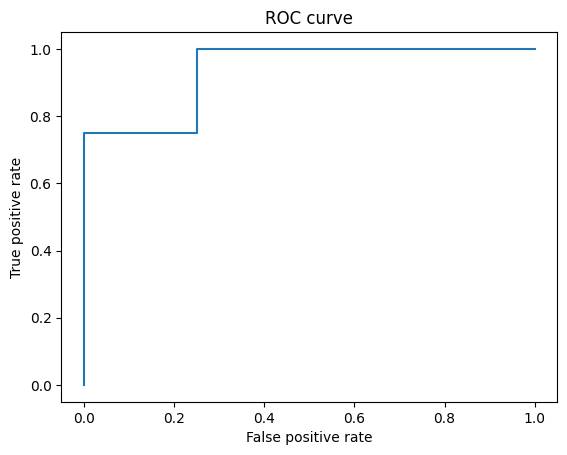

AUC:  0.9375


In [ ]:
#ROC-AUC curve
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve,roc_auc_score

y_actual = [0,0,0,0,1,1,1,1]
#predicted values
y_pred = [0.1, 0.2, 0.35, 0.6, 0.45, 0.7, 0.8, 0.95]
fpr,tpr,threshold = roc_curve(y_actual,y_pred)
auc = roc_auc_score(y_actual,y_pred)
plt.plot(fpr,tpr)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")

plt.show()
print("AUC: ",auc)

Average precision:  0.95


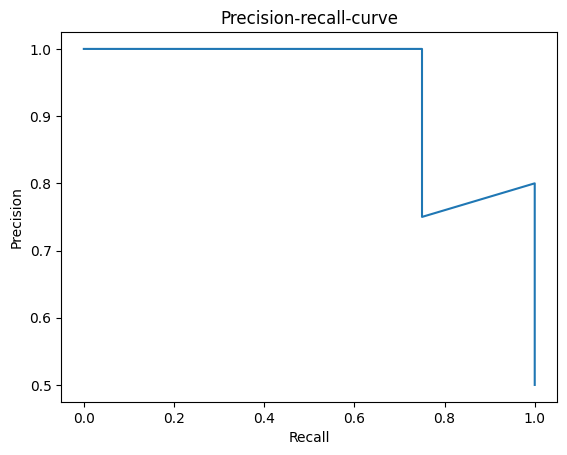

In [ ]:
#precision recall curve
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
import matplotlib.pyplot as plt

y_actual = [0,0,0,0,1,1,1,1]
y_pred = [0.1, 0.2, 0.35, 0.6, 0.45, 0.7, 0.8, 0.95]
precision,recall,threshold = precision_recall_curve(y_actual,y_pred)
ap = average_precision_score(y_actual,y_pred)
print("Average precision: ",ap)
plt.plot(recall,precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall-curve")
plt.show()

Information theory and feature selection

In [ ]:
#info theory = gives mathematical ways to measure the uncertainty
#TO-DO: entropy, information gain and decision tree splitting

# Questions on unit-1

In [ ]:
#question-1
"""
A fair coin is tossed 100 times.
Calculate: •
 Number of heads  •
 Number of tails •
 Experimental probability of Head  •
 Experimental probability of Tail """
import random
trails = 100
heads =0
tails=0
for i in range(trails):
  res = random.choice(["H","T"])
  if res =="H":
    heads+=1
  else:
    tails +=1

print("Number of heads: ",heads)
print("Number of tails: ",tails)
print("Experimental probability of head: ",heads/trails)
print("Experimental probability of tail: ",tails/trails)

Number of heads:  49
Number of tails:  51
Experimental probability of head:  0.49
Experimental probability of tail:  0.51


In [ ]:
"""
 check Effect of the number of trials Repeat the coin-toss experiment for: n=10, 100, 1,000, 10,000
"""
def check_Effect(trials):
  heads =0
  tails=0
  for i in range(trials):
    res = random.choice(["H","T"])
    if res =="H":
      heads+=1
    else:
      tails+=1
  print("The obseravtion for the number of trials= ",trials)
  print("Number of heads: ",heads)
  print("Number of tails ",tails)
  print("Probability of head: ",heads/trials)
  print("Probability of tail: ",tails/trials)

check_Effect(10)
check_Effect(100)
check_Effect(1000)
check_Effect(10000)

The obseravtion for the number of trials=  10
Number of heads:  2
Number of tails  8
Probability of head:  0.2
Probability of tail:  0.8
The obseravtion for the number of trials=  100
Number of heads:  47
Number of tails  53
Probability of head:  0.47
Probability of tail:  0.53
The obseravtion for the number of trials=  1000
Number of heads:  516
Number of tails  484
Probability of head:  0.516
Probability of tail:  0.484
The obseravtion for the number of trials=  10000
Number of heads:  5000
Number of tails  5000
Probability of head:  0.5
Probability of tail:  0.5


In [ ]:
"""A fair die is rolled 6,000 times.
Calculate the experimental probability of each outcome: S={1,2,3,4,5,6} """


# Unit-2

In [ ]:
"""To simulate the die 10,000 times and estimate each outcome's probability:"""
import random

trials =10000
count = [0]*7
for i in range(trials):
  res = random.randint(1,6)
  count[res] +=1


for i in range(1,7):
  print(i,count[i]/trials)

1 0.1696
2 0.1664
3 0.1663
4 0.1636
5 0.1642
6 0.1699


In [ ]:
#random variable
#toss coin 3 times and the number of times the heads appears
import random
heads =0
tosses=3
for i in range(tosses):
  res = random.choice(["H","T"])
  print(res)

  if res =="H":
    heads+=1


print("Number of heads: ",heads)

H
T
T
Number of heads:  1


In [ ]:
#uniform distibution
from scipy.stats import randint
import numpy as np
n=8
res = randint(1,n+1)
for x in range(1,n+1):
  print("PMF for each outcome: ",res.pmf(x))

print("Variance: ",res.var())
print("Expected value: ",res.mean())
print("Standrd deviation: ",res.std())
#for X>5
print("Value: ",res.sf(5))

PMF for each outcome:  0.125
PMF for each outcome:  0.125
PMF for each outcome:  0.125
PMF for each outcome:  0.125
PMF for each outcome:  0.125
PMF for each outcome:  0.125
PMF for each outcome:  0.125
PMF for each outcome:  0.125
Variance:  5.25
Expected value:  4.5
Standrd deviation:  2.29128784747792
Value:  0.375


In [ ]:
#bernoulli
from scipy.stats import bernoulli
import numpy as np
p =0.4
size =20
res = bernoulli(p)
print("PMF for X=1 ",res.pmf(1))
print("PMF for X=0 ",res.pmf(0))
print("Expected value: ",res.mean())
print("Variencw: ",res.var())
print("std: ",res.std())

#for 20 samples
samples = np.random.binomial(n-1,p=p,size=size)
print("Generated outcomes: ",samples)
print("Number of purchases: ",np.sum(samples==1))
print("Number of non-purchases: ",np.sum(samples==0))
print("Emperical value",np.mean(samples))

PMF for X=1  0.4
PMF for X=0  0.6
Expected value:  0.4
Variencw:  0.24
std:  0.4898979485566356
Generated outcomes:  [4 3 3 4 2 4 4 1 1 4 3 5 3 2 2 1 3 2 3 2]
Number of purchases:  3
Number of non-purchases:  0
Emperical value 2.8


In [ ]:
#bernoulli
from scipy.stats import bernoulli
import numpy as np

p=0.4
res = bernoulli(p)
print(res.pmf(0))
print(res.pmf(1))
print(res.var())
print(res.mean())
print(res.std())

#for 20 such visitors
samples = np.random.binomial(n=1,p=p,size=20)

#emperical valus
print("Number of purchases: ",np.sum(samples==1))
print("Number of non purchases: ",np.sum(samples==0))
print("Varience: ",np.var(samples))
print("mean: ",np.mean(samples))

0.6
0.4
0.24
0.4
0.4898979485566356
Number of purchases:  7
Number of non purchases:  13
Varience:  0.22749999999999995
mean:  0.35


In [ ]:
#binomial
from scipy.stats import binom
import numpy as np

n=12
p=0.1
k=2
res = binom(n,p)
print("PMF: ",res.pmf(k))
print("VArince: ",res.var())
print("Value: ",res.mean())

#for 100 bacthes
samples = np.random.binomial(n=n,p=p,size=100)
print("Mean: ",np.mean(samples))
print("For X=2: ",np.mean(samples==2))


PMF:  0.230127770466
VArince:  1.08
Value:  1.2000000000000002
Mean:  1.18
For X=2:  0.24


In [ ]:
#geometric distribution
from scipy.stats import geom
import numpy as np
p=0.25
k=3
res = geom(p)
print("PMF: ",res.pmf(k))
print("Var: ",res.var())
print("Mean: ",res.mean())
print("std: ",res.std())

#for 100 trials
samp = np.random.geometric(p=p,size=100)
print()

PMF:  0.140625
Var:  12.0
Mean:  4.0
std:  3.4641016151377544



In [ ]:
#hypergeometric
from scipy.stats import hypergeom
import numpy as np

N=15
K=5
n=4
k=2
res = hypergeom(N,K,n)
print("PMF: ",res.pmf(k))
print("var: ",res.var())
print("Mean: ",res.mean())

#1000 samples
samples = np.random.hypergeometric(ngood=N-K,nbad=K,nsample=n,size=1000)

PMF:  0.3296703296703297
var:  0.6984126984126984
Mean:  1.3333333333333333


In [ ]:
"""
	A monitoring system checks 12 independent server requests during each minute. Each request has a 0.20 probability of failing. Let X be the number of failed requests in one minute.
Write Python code to:
	Identify the distribution of X, its parameters, and its possible values.
	Simulate 20,000 minutes and calculate the empirical PMF for every possible value of X.
	Calculate the theoretical PMF and plot it alongside the empirical PMF.
	Calculate the empirical and theoretical expectation and variance. Present the four values in a table.
	Estimate P(X≥4)from the simulation and calculate it theoretically.

"""
from scipy.stats import binom
import numpy as np

p=0.20
n=12
pmf=[]*12
res = binom(n,p)
for i in range(n):
  pmf[i] = res.pmf(i)

